# 129 · Fine-tuning ablations on MiniVLA: dataset size and LoRA rank, with error bars
The model is S11's MiniVLA v2 (SmolVLM-256M + LoRA + flow-matching action expert) on the "single" scene.
Each run fine-tunes from the same pretrained VLM; only the number of demonstrations or the LoRA rank changes.

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, scene_dataset
from vlacourse.torch_data import TableTopDataset
from vlacourse.minivla import train_flow, MiniVLAFlowPolicy

SCENE = "single"
DATA = scene_dataset(SCENE)
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
STEPS, BS, N_EVAL, H = 3500, 16, 40, 16
os.makedirs("results", exist_ok=True)
DS = TableTopDataset(DATA, episodes=range(450), horizon=H, use_images=False)
ENV = TableTop(scene=SCENE, cameras=("front",), image_size=(128, 128), seed=0)

def run(n_eps, rank):
    key = f"n{n_eps}_r{rank}"
    path = f"results/ablation_{key}.json"
    if os.path.exists(path):
        return json.load(open(path))
    t0 = time.time(); vla = train_flow(DS, n_eps=n_eps, rank=rank, steps=STEPS, bs=BS, device=device)
    r = evaluate(ENV, MiniVLAFlowPolicy(vla, ENV, execute=8, steps=10, ds=DS), n_episodes=N_EVAL, seed=50_000)
    out = dict(success=r["success"], ci=list(r["ci"]), minutes=(time.time() - t0) / 60)
    json.dump(out, open(path, "w")); del vla; torch.cuda.empty_cache()
    print(f"{key}: success {out['success']:.2f} CI [{out['ci'][0]:.2f}, {out['ci'][1]:.2f}] ({out['minutes']:.0f} min)")
    return out

In [2]:
size_runs = {n: run(n, 64) for n in [50, 150, 450]}

In [3]:
rank_runs = {r: run(450, r) for r in [4, 16, 64]}

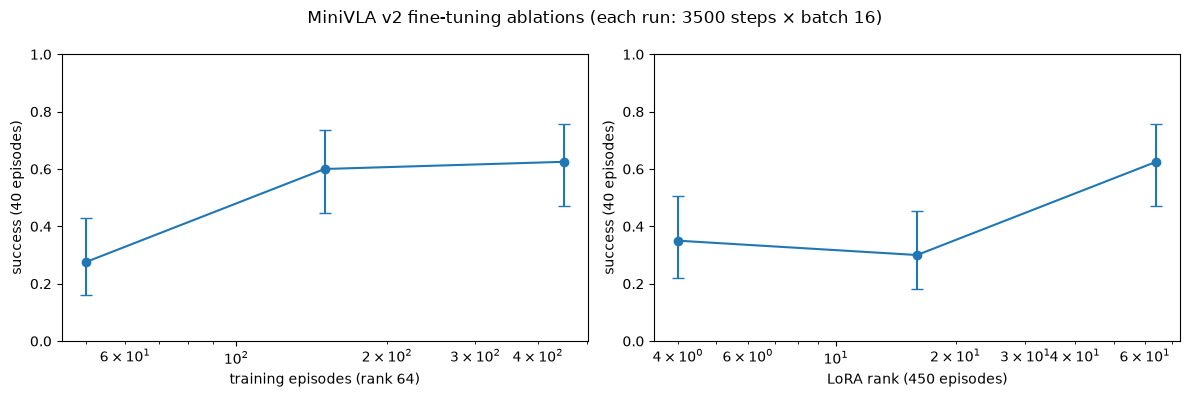

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, runs, xl in [(ax[0], size_runs, "training episodes (rank 64)"), (ax[1], rank_runs, "LoRA rank (450 episodes)")]:
    xs = sorted(runs); ys = np.array([runs[x]["success"] for x in xs]); ci = np.array([runs[x]["ci"] for x in xs])
    err = np.clip([ys - ci[:, 0], ci[:, 1] - ys], 0, None)          # Wilson bounds can round a hair past the point estimate
    a.errorbar(xs, ys, yerr=err, marker="o", capsize=4); a.set_xscale("log"); a.set_ylim(0, 1); a.set_xlabel(xl); a.set_ylabel(f"success ({N_EVAL} episodes)")
plt.suptitle(f"MiniVLA v2 fine-tuning ablations (each run: {STEPS} steps × batch {BS})"); plt.tight_layout(); plt.show()